# Global Zipf Fit on Pride and Prejudice

This notebook demonstrates Maximum Likelihood Estimation (MLE) fitting of Zipf and Zipf-Mandelbrot models to word frequencies from a text sample, using the approach described in the research paper.

In [1]:
# Install dependencies (for Colab and clean environments)
import sys
if 'google.colab' in sys.modules:
    !pip install -q numpy scipy matplotlib

In [2]:
import json
import re
import numpy as np
from collections import Counter
from scipy.optimize import minimize
from scipy.stats import ks_1samp
import argparse
from pathlib import Path
import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

Matplotlib is building the font cache; this may take a moment.


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-624cdf-local-zipfian-curvature-as-narrative/main/round-2/experiment-2/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

data = load_data()

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


In [4]:
# Config
N_BOOT = 10  # Start small for demo

## Tokenization and Freq Calculation

In [5]:
def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

examples = data["datasets"][0]["examples"]
tokens_novel = []
examples.sort(key=lambda x: x["metadata_token_start"])
for i, ex in enumerate(examples):
    text = json.loads(ex["input"])["text"]
    tokens_novel.extend(tokenize(text))

counts = Counter(tokens_novel)
freqs = np.array(sorted(counts.values(), reverse=True))

## Fitting Models

In [6]:
def zipf_mandelbrot_pdf(s, b, n):
    r_arr = np.arange(1, n + 1)
    probs = 1.0 / np.power(r_arr + b, s)
    return probs / np.sum(probs)

def zipf_pdf(s, n):
    r_arr = np.arange(1, n + 1)
    probs = 1.0 / np.power(r_arr, s)
    return probs / np.sum(probs)

def log_likelihood_zm(params, freqs):
    s, b = params
    n = len(freqs)
    probs = zipf_mandelbrot_pdf(s, b, n)
    probs = np.maximum(probs, 1e-10)
    return -np.sum(freqs * np.log(probs))

def log_likelihood_zipf(s, freqs):
    n = len(freqs)
    probs = zipf_pdf(s, n)
    probs = np.maximum(probs, 1e-10)
    return -np.sum(freqs * np.log(probs))

def fit_zipf(freqs):
    res = minimize(lambda s: log_likelihood_zipf(s[0], freqs), [1.0], bounds=[(0.01, 5.0)], method='L-BFGS-B')
    return res.x[0], res.fun, 2 * 1 + 2 * res.fun

def fit_zipf_mandelbrot(freqs):
    res = minimize(lambda p: log_likelihood_zm(p, freqs), [1.0, 1.0], bounds=[(0.01, 5.0), (0.0, 100.0)], method='L-BFGS-B')
    return res.x[0], res.x[1], res.fun, 2 * 2 + 2 * res.fun

s_zipf, nll_zipf, aic_zipf = fit_zipf(freqs)
s_zm, b_zm, nll_zm, aic_zm = fit_zipf_mandelbrot(freqs)

## Results

Zipf: s=0.5582, AIC=518.67
Zipf-Mandelbrot: s=0.5582, b=0.0000, AIC=520.67


findfont: Failed to find font weight normal for CMU Serif, now using 500.


findfont: Failed to find font weight normal for CMU Serif, now using 500.


findfont: Failed to find font weight normal for CMU Serif, now using 500.


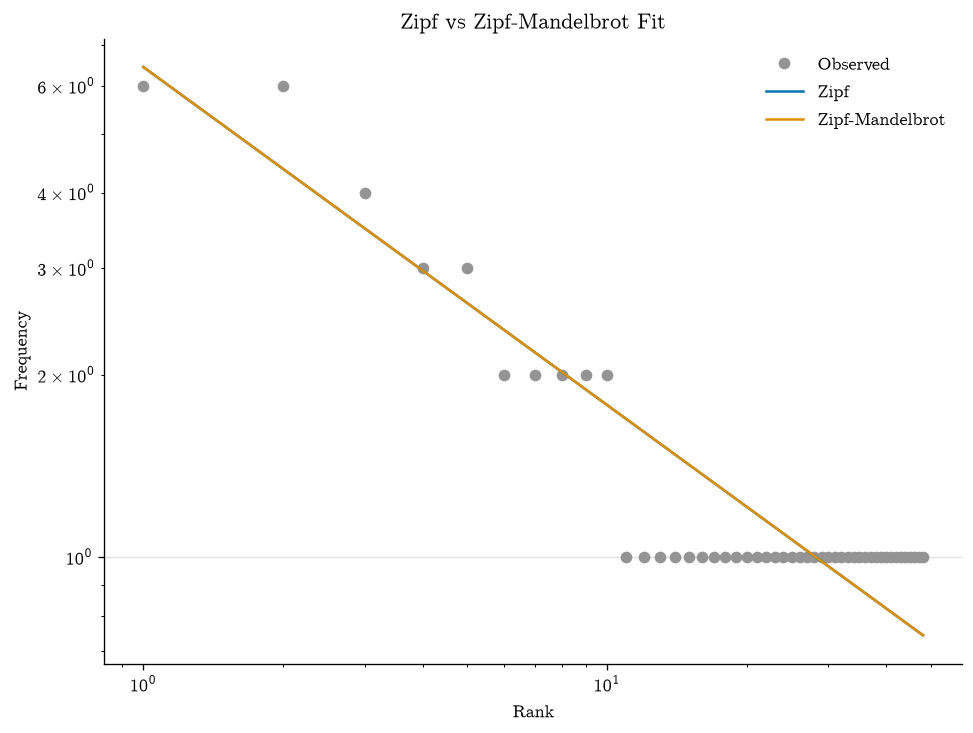

In [7]:
print(f"Zipf: s={s_zipf:.4f}, AIC={aic_zipf:.2f}")
print(f"Zipf-Mandelbrot: s={s_zm:.4f}, b={b_zm:.4f}, AIC={aic_zm:.2f}")

ranks = np.arange(1, len(freqs) + 1)
plt.figure(figsize=(8, 6))
plt.loglog(ranks, freqs, 'o', label='Observed', color=COLOURS['baseline'])
plt.loglog(ranks, zipf_pdf(s_zipf, len(freqs)) * np.sum(freqs), '-', label='Zipf', color=COLOURS['method'])
plt.loglog(ranks, zipf_mandelbrot_pdf(s_zm, b_zm, len(freqs)) * np.sum(freqs), '-', label='Zipf-Mandelbrot', color=COLOURS['other_1'])
plt.legend()
plt.xlabel('Rank')
plt.ylabel('Frequency')
plt.title('Zipf vs Zipf-Mandelbrot Fit')
plt.show()